# Which countries have seen the most growth in Repair Cafe branches?

**Author:** Kandra

A "branch" here is a Repair Cafe that logged at least one repair in the dataset. We count each branch from the year of its first logged repair, so these counts show growth in *reporting* branches, not necessarily all branches that exist.

In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt

repairs = pd.read_csv("repairs.csv", parse_dates=["repair_date"])
repairs = repairs.dropna(subset=["repair_date", "country", "repair_cafe_number"])
repairs["year"] = repairs["repair_date"].dt.year
print(repairs["repair_date"].min(), "to", repairs["repair_date"].max())
repairs.groupby("year").size()

2015-04-04 00:00:00 to 2026-08-07 00:00:00


year
2015       28
2016      139
2017     4075
2018     9518
2019    15491
2020     6686
2021     5813
2022    15096
2023    29406
2024    39981
2025    45165
2026     7346
dtype: int64

In [2]:
# First year each branch appears, then cumulative branches per country
branches = (
    repairs.groupby(["country", "repair_cafe_number"])["year"].min()
    .rename("first_year").reset_index()
)
years = range(int(repairs["year"].min()), int(repairs["year"].max()) + 1)
new_branches = branches.groupby(["country", "first_year"]).size().unstack(fill_value=0).reindex(columns=years, fill_value=0)
cumulative = new_branches.cumsum(axis=1)

# Compare 2019 with the last full year in the data
START = 2019
last = repairs["repair_date"].max()
END = last.year if last.month == 12 else last.year - 1
print("Comparing", START, "to", END)

growth_table = pd.DataFrame({"branches_start": cumulative[START], "branches_end": cumulative[END]})
growth_table["added"] = growth_table["branches_end"] - growth_table["branches_start"]
growth_table["pct_growth"] = (growth_table["added"] / growth_table["branches_start"].where(growth_table["branches_start"] >= 5) * 100).round(0)
growth_table = growth_table.sort_values("added", ascending=False)
growth_table.head(10)

Comparing 2019 to 2025


,branches_start,branches_end,added,pct_growth
country,,,,
NL,51,142,91,178.0
GB,8,82,74,925.0
FR,11,81,70,636.0
US,6,30,24,400.0
DE,3,25,22,NaN
AU,4,17,13,NaN
CA,4,12,8,NaN
BE,2,10,8,NaN
IT,0,4,4,NaN


`pct_growth` is only computed for countries that already had at least 5 branches in the start year.

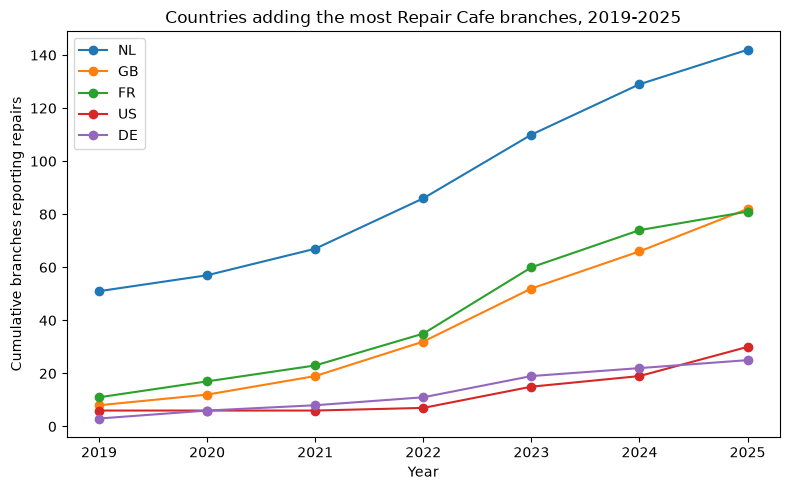

In [3]:
top5 = growth_table.head(5).index
cols = [y for y in cumulative.columns if START <= y <= END]

fig, ax = plt.subplots(figsize=(8, 5))
for c in top5:
    ax.plot(cols, cumulative.loc[c, cols], marker="o", label=c)
ax.set_xlabel("Year")
ax.set_ylabel("Cumulative branches reporting repairs")
ax.set_title(f"Countries adding the most Repair Cafe branches, {START}-{END}")
ax.legend()
plt.tight_layout()
plt.savefig("figures/kandra_branch_growth.png", dpi=150)
plt.show()

## Takeaway

In [4]:
for c, row in growth_table.head(5).iterrows():
    print(f"{c}: {int(row['branches_start'])} -> {int(row['branches_end'])} branches (+{int(row['added'])})")

summary = {
    "start_year": START,
    "end_year": int(END),
    "n_countries": int(repairs["country"].nunique()),
    "top_growth": [[c, int(r["branches_start"]), int(r["branches_end"])] for c, r in growth_table.head(5).iterrows()],
}
with open("figures/kandra_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

NL: 51 -> 142 branches (+91)
GB: 8 -> 82 branches (+74)
FR: 11 -> 81 branches (+70)
US: 6 -> 30 branches (+24)
DE: 3 -> 25 branches (+22)
